<a href="https://colab.research.google.com/github/JamesFrank-Space/Solar-Wind-Prediction-Study/blob/main/Copy_of_solar_wind_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
print("My Solar Wind Research Project")
print("Researcher: Jmaes Frank")
print("Start Date: 20 March, 2026")

My Solar Wind Research Project
Researcher: Jmaes Frank
Start Date: 20 March, 2026


In [15]:

import json
import urllib.request
import pandas as pd

url = "https://services.swpc.noaa.gov/json/rtsw/rtsw_wind_1m.json"

request = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=30) as response:
    solar_wind_data = json.loads(response.read().decode("utf-8"))

df = pd.DataFrame(solar_wind_data)
df["time_tag"] = pd.to_datetime(df["time_tag"], errors="coerce")

for column in ["proton_density", "proton_speed", "proton_temperature"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("NOAA solar wind data downloaded successfully.")
print("Dataset dimensions:", df.shape)
display(df.head())


NOAA solar wind data downloaded successfully.
Dataset dimensions: (3226, 31)


,time_tag,active,source,proton_speed,proton_temperature,proton_density,proton_vx_gse,proton_vy_gse,proton_vz_gse,proton_vx_gsm,...,alpha_vz_gsm,alpha_sample_size,max_convergence_flag,max_data_flag,max_error_count_flag,max_processing_flag,max_range_flag,max_sample_count_flag,max_telemetry_flag,overall_quality
0,2026-10-29 14:11:00,True,SOLAR1,344.80,41781.0,2.09,-344.1,16.9,-13.3,-344.1,...,None,None,0,0,0,0,0,0,0,0
1,2026-10-29 14:10:02,False,IMAP,349.81,27739.0,7.26,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0
2,2026-10-29 14:10:00,True,SOLAR1,344.00,38948.0,2.12,-343.5,13.5,-13.4,-343.5,...,None,None,0,0,0,0,0,0,0,0
3,2026-10-29 14:09:02,False,IMAP,348.26,29505.0,7.03,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0
4,2026-10-29 14:08:02,False,IMAP,347.60,30296.0,6.98,NaN,NaN,NaN,NaN,...,None,None,0,0,0,0,0,0,0,0


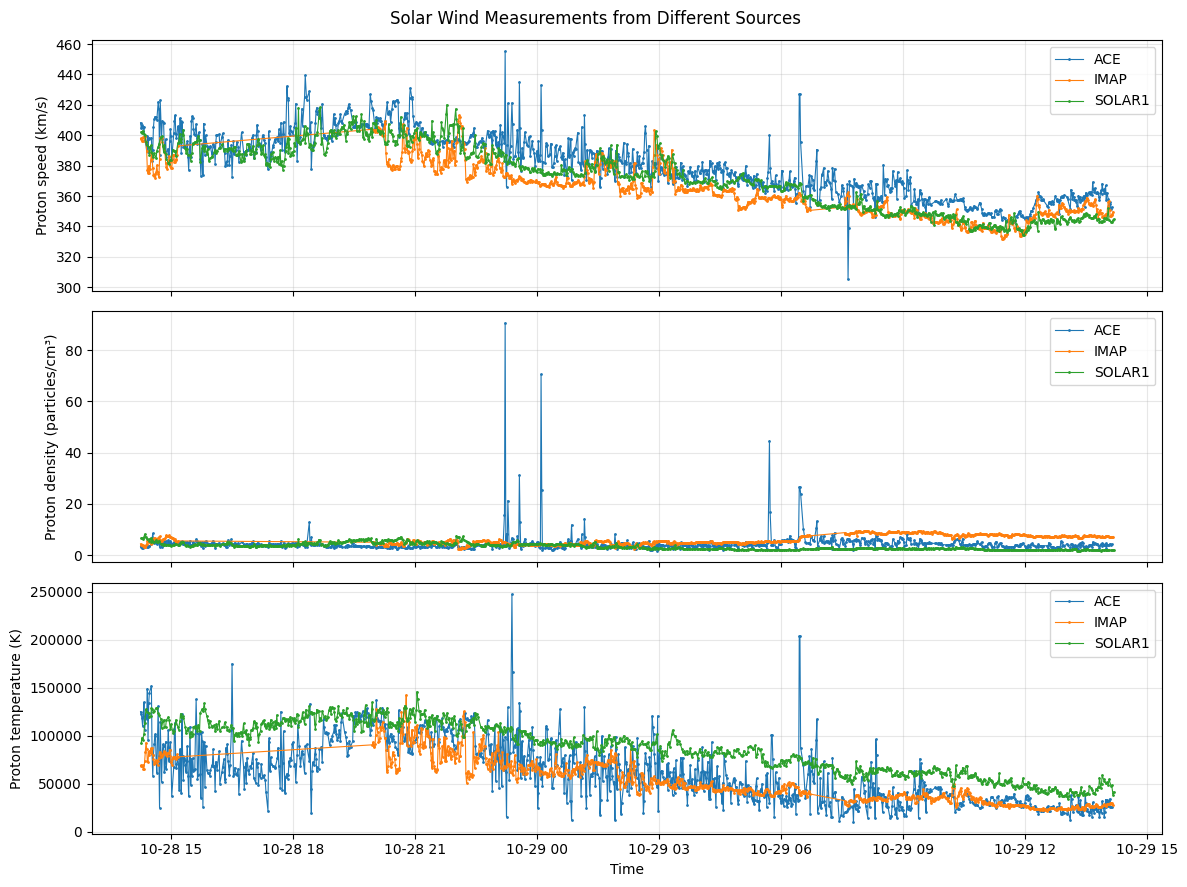

In [16]:

# STEP 2: Plot the three solar wind measurements over time

import matplotlib.pyplot as plt

plot_df = df.sort_values("time_tag").copy()

measurements = [
    ("proton_speed", "Proton speed (km/s)"),
    ("proton_density", "Proton density (particles/cm³)"),
    ("proton_temperature", "Proton temperature (K)")
]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (column, label) in zip(axes, measurements):
    for source, group in plot_df.groupby("source"):
        group = group.dropna(subset=["time_tag", column])
        ax.plot(group["time_tag"], group[column],
                marker=".", markersize=2, linewidth=0.8,
                label=source)

    ax.set_ylabel(label)
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time")
fig.suptitle("Solar Wind Measurements from Different Sources")
plt.tight_layout()
plt.show()


In [17]:

# STEP 3: Check data quality

print("Missing values in key measurements:")
print(df[[
    "proton_speed",
    "proton_density",
    "proton_temperature"
]].isna().sum())

print("\nRepeated timestamps:", df["time_tag"].duplicated().sum())

print("\nMeasurements by source:")
print(df["source"].value_counts())


Missing values in key measurements:
proton_speed          2
proton_density        2
proton_temperature    2
dtype: int64

Repeated timestamps: 874

Measurements by source:
source
ACE       1118
IMAP      1099
SOLAR1    1009
Name: count, dtype: int64


In [18]:

# STEP 4: Inspect repeated timestamps

print("Example records with repeated timestamps:")

repeated = df[df["time_tag"].duplicated(keep=False)]

display(
    repeated[
        ["time_tag", "source", "proton_speed",
         "proton_density", "proton_temperature"]
    ].sort_values("time_tag").head(15)
)


Example records with repeated timestamps:


,time_tag,source,proton_speed,proton_density,proton_temperature
3223,2026-10-28 14:16:00,ACE,404.75,3.25,122927.0
3222,2026-10-28 14:16:00,SOLAR1,402.30,6.72,92496.0
3219,2026-10-28 14:17:00,SOLAR1,401.50,6.60,98096.0
3220,2026-10-28 14:17:00,ACE,406.42,2.91,118469.0
3216,2026-10-28 14:18:00,SOLAR1,403.00,6.46,95456.0
3217,2026-10-28 14:18:00,ACE,405.38,2.88,110171.0
3211,2026-10-28 14:20:00,SOLAR1,401.10,6.96,102014.0
3212,2026-10-28 14:20:00,ACE,405.68,3.70,135148.0
3208,2026-10-28 14:21:00,SOLAR1,400.30,8.20,113572.0
3209,2026-10-28 14:21:00,ACE,396.31,3.09,106284.0


In [19]:

# STEP 5: Prepare ACE observations for analysis

ace_df = df[df["source"] == "ACE"].copy()

ace_df = ace_df.sort_values("time_tag")

# Keep only the time and three main measurements
ace_df = ace_df[
    ["time_tag", "proton_speed",
     "proton_density", "proton_temperature"]
]

print("ACE dataset dimensions:", ace_df.shape)
print("\nMissing values:")
print(ace_df.isna().sum())

print("\nFirst five ACE observations:")
display(ace_df.head())


ACE dataset dimensions: (1118, 4)

Missing values:
time_tag              0
proton_speed          0
proton_density        0
proton_temperature    0
dtype: int64

First five ACE observations:


,time_tag,proton_speed,proton_density,proton_temperature
3225,2026-10-28 14:15:00,408.25,3.44,125311.0
3223,2026-10-28 14:16:00,404.75,3.25,122927.0
3220,2026-10-28 14:17:00,406.42,2.91,118469.0
3217,2026-10-28 14:18:00,405.38,2.88,110171.0
3214,2026-10-28 14:19:00,405.08,3.35,120741.0


In [20]:

# STEP 6: Check gaps between ACE observations

ace_df["time_gap_minutes"] = (
    ace_df["time_tag"].diff().dt.total_seconds() / 60
)

print("Time gap in minutes between consecutive observations:")
print(ace_df["time_gap_minutes"].value_counts().sort_index())

print("\nLargest time gaps:")
display(
    ace_df.nlargest(10, "time_gap_minutes")[
        ["time_tag", "time_gap_minutes"]
    ]
)


Time gap in minutes between consecutive observations:
time_gap_minutes
1.0    881
2.0    175
3.0     50
4.0      8
6.0      1
7.0      2
Name: count, dtype: int64

Largest time gaps:


,time_tag,time_gap_minutes
651,2026-10-29 09:48:00,7.0
614,2026-10-29 10:04:00,7.0
246,2026-10-29 12:33:00,6.0
2955,2026-10-28 16:44:00,4.0
2805,2026-10-28 18:24:00,4.0
2728,2026-10-28 19:16:00,4.0
2409,2026-10-28 21:40:00,4.0
1096,2026-10-29 06:33:00,4.0
733,2026-10-29 09:16:00,4.0
176,2026-10-29 13:02:00,4.0


In [21]:

# STEP 7: Test linear interpolation on hidden measurements

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Use ACE proton speed, arranged at one-minute intervals
speed = (
    ace_df.drop_duplicates("time_tag")
    .set_index("time_tag")["proton_speed"]
    .sort_index()
)

full_time = pd.date_range(
    start=speed.index.min(),
    end=speed.index.max(),
    freq="1min"
)

speed = speed.reindex(full_time)

# Only test values that were actually measured
known_positions = np.flatnonzero(speed.notna().to_numpy())

# Hide 15% of known measurements at random
rng = np.random.default_rng(42)
n_hide = max(1, int(0.15 * len(known_positions)))
hidden_positions = rng.choice(
    known_positions, size=n_hide, replace=False
)

true_values = speed.iloc[hidden_positions].copy()
test_speed = speed.copy()
test_speed.iloc[hidden_positions] = np.nan

# Estimate the hidden values using interpolation
predictions = test_speed.interpolate(
    method="linear", limit_area="inside"
).iloc[hidden_positions]

# Compare predictions with the real measurements
valid = predictions.notna()

mae = mean_absolute_error(
    true_values[valid],
    predictions[valid]
)

print("Hidden measurements:", n_hide)
print("Successfully predicted:", int(valid.sum()))
print("Mean Absolute Error:", round(mae, 2), "km/s")


Hidden measurements: 167
Successfully predicted: 167
Mean Absolute Error: 5.24 km/s


In [22]:

# STEP 8: Compare interpolation with forward fill

# Recreate the same hidden measurements
test_speed = speed.copy()
test_speed.iloc[hidden_positions] = np.nan

# Method 1: Linear interpolation
interpolation_predictions = test_speed.interpolate(
    method="linear", limit_area="inside"
).iloc[hidden_positions]

# Method 2: Forward fill
forward_fill_predictions = test_speed.ffill().iloc[hidden_positions]

# Compare both methods on the same hidden values
true_values = speed.iloc[hidden_positions]

interpolation_mae = mean_absolute_error(
    true_values, interpolation_predictions
)

forward_fill_mae = mean_absolute_error(
    true_values, forward_fill_predictions
)

print("Prediction comparison for proton speed")
print("---------------------------------------")
print("Linear interpolation MAE:",
      round(interpolation_mae, 2), "km/s")
print("Forward fill MAE:",
      round(forward_fill_mae, 2), "km/s")


Prediction comparison for proton speed
---------------------------------------
Linear interpolation MAE: 5.24 km/s
Forward fill MAE: 6.14 km/s


In [23]:
%whos

Variable                    Type             Data/Info
------------------------------------------------------
ace_df                      DataFrame                        time_tag <...>\n[1118 rows x 5 columns]
ax                          Axes             Axes(0.0807523,0.0647531;0.892049x0.278752)
axes                        ndarray          3: 3 elems, type `object`, 24 bytes
candidate_ends              ndarray          236: 236 elems, type `int64`, 1888 bytes
column                      str              proton_temperature
df                          DataFrame                        time_tag <...>n[3226 rows x 31 columns]
end_pos                     int64            834
fig                         Figure           Figure(1200x900)
forward_fill_gap            Series           2026-10-29 04:03:00    37<...>ton_speed, dtype: float64
forward_fill_gap_mae        float            2.789999999999998
forward_fill_mae            float            6.142694610778445
forward_fill_predictions    Se

In [24]:
# Test a continuous gap of five missing minutes

# Find seven consecutive valid observations:
# one before the gap, five inside it, and one after it
valid_seven = speed.notna().rolling(window=7).sum().eq(7)
candidate_ends = np.flatnonzero(valid_seven.to_numpy())

if len(candidate_ends) == 0:
    print("No suitable block found. We need to check the data.")
else:
    # Select a block near the middle of the data
    end_pos = candidate_ends[len(candidate_ends) // 2]
    start_pos = end_pos - 6

    # Hide the five middle observations
    gap_positions = np.arange(start_pos + 1, start_pos + 6)

    test_speed_gap = speed.copy()
    test_speed_gap.iloc[gap_positions] = np.nan

    # Method 1: Linear interpolation
    interpolation_gap = test_speed_gap.interpolate(
        method="linear", limit_area="inside"
    ).iloc[gap_positions]

    # Method 2: Forward fill
    forward_fill_gap = test_speed_gap.ffill().iloc[gap_positions]

    # Recover the original values for evaluation
    true_gap_values = speed.iloc[gap_positions]

    # Calculate the errors
    interpolation_gap_mae = mean_absolute_error(
        true_gap_values, interpolation_gap
    )

    forward_fill_gap_mae = mean_absolute_error(
        true_gap_values, forward_fill_gap
    )

    print("Five-minute gap test")
    print("--------------------")
    print("Linear interpolation MAE:",
          round(interpolation_gap_mae, 2), "km/s")
    print("Forward fill MAE:",
          round(forward_fill_gap_mae, 2), "km/s")

    print("\nOriginal and estimated values:")
    print("Actual:", true_gap_values.to_list())
    print("Interpolation:", interpolation_gap.to_list())
    print("Forward fill:", forward_fill_gap.to_list())

Five-minute gap test
--------------------
Linear interpolation MAE: 2.96 km/s
Forward fill MAE: 2.79 km/s

Original and estimated values:
Actual: [377.31, 382.59, 376.64, 369.44, 376.67]
Interpolation: [376.8933333333333, 376.9866666666667, 377.08000000000004, 377.17333333333335, 377.26666666666665]
Forward fill: [376.8, 376.8, 376.8, 376.8, 376.8]


In [25]:
%whos

Variable                    Type             Data/Info
------------------------------------------------------
ace_df                      DataFrame                        time_tag <...>\n[1118 rows x 5 columns]
ax                          Axes             Axes(0.0807523,0.0647531;0.892049x0.278752)
axes                        ndarray          3: 3 elems, type `object`, 24 bytes
candidate_ends              ndarray          235: 235 elems, type `int64`, 1880 bytes
column                      str              proton_temperature
df                          DataFrame                        time_tag <...>n[3226 rows x 31 columns]
end_pos                     int64            833
fig                         Figure           Figure(1200x900)
forward_fill_gap            Series           2026-10-29 04:03:00    37<...>ton_speed, dtype: float64
forward_fill_gap_mae        float            2.789999999999998
forward_fill_mae            float            6.142694610778445
forward_fill_predictions    Se

In [26]:
# Predict the next minute's proton speed
# using the current minute's speed

forecast_data = pd.DataFrame({
    "current_speed": speed,
    "next_speed": speed.shift(-1)
}).dropna()

# Keep the data in chronological order
split = int(len(forecast_data) * 0.8)
test = forecast_data.iloc[split:]

# Baseline prediction: speed stays the same
predicted_speed = test["current_speed"]
actual_speed = test["next_speed"]

# Measure prediction error
baseline_mae = mean_absolute_error(
    actual_speed, predicted_speed
)

print("One-minute solar wind speed prediction")
print("Test observations:", len(test))
print("Baseline MAE:", round(baseline_mae, 2), "km/s")

One-minute solar wind speed prediction
Test observations: 177
Baseline MAE: 2.15 km/s


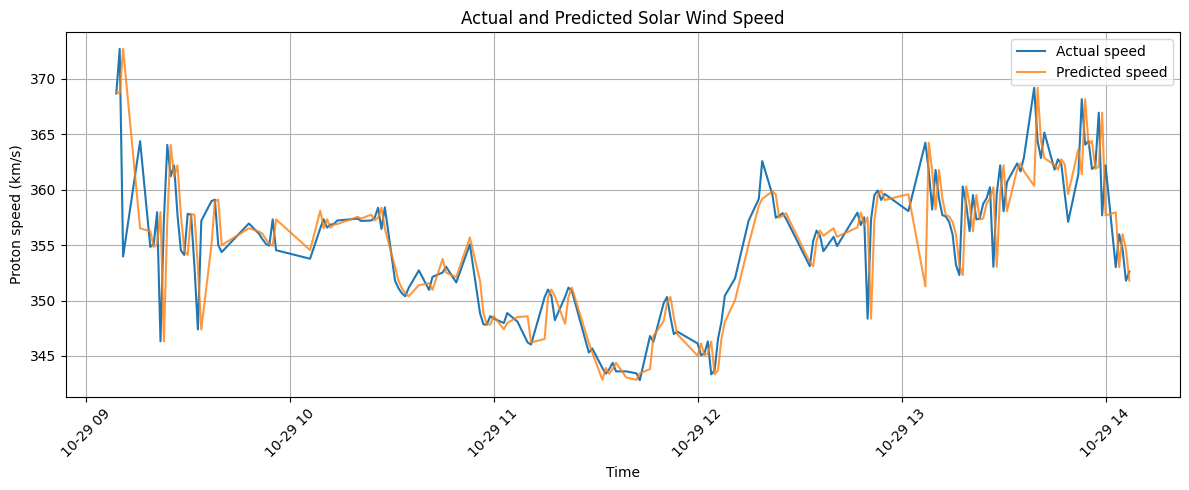

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    actual_speed.index,
    actual_speed,
    label="Actual speed"
)

plt.plot(
    predicted_speed.index,
    predicted_speed,
    label="Predicted speed",
    alpha=0.8
)

plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.title("Actual and Predicted Solar Wind Speed")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
# Prepare data for one-minute-ahead prediction

prediction_data = pd.DataFrame({
    "speed_t": speed,
    "speed_t1": speed.shift(1),
    "speed_t2": speed.shift(2),
    "speed_t3": speed.shift(3),
    "speed_t4": speed.shift(4),
    "speed_t5": speed.shift(5),
    "target": speed.shift(-1)
}).dropna()

print("Prediction data prepared")
print("Number of observations:", len(prediction_data))
display(prediction_data.head())

Prediction data prepared
Number of observations: 235


,speed_t,speed_t1,speed_t2,speed_t3,speed_t4,speed_t5,target
2026-10-28 14:20:00,405.68,405.08,405.38,406.42,404.75,408.25,396.31
2026-10-28 14:36:00,411.86,410.43,405.16,390.33,383.11,398.33,411.84
2026-10-28 14:37:00,411.84,411.86,410.43,405.16,390.33,383.11,411.67
2026-10-28 14:38:00,411.67,411.84,411.86,410.43,405.16,390.33,410.00
2026-10-28 14:51:00,388.92,392.59,408.01,408.72,409.49,397.83,397.46


In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Select the input features
features = [
    "speed_t",
    "speed_t1",
    "speed_t2",
    "speed_t3",
    "speed_t4",
    "speed_t5"
]

X = prediction_data[features]
y = prediction_data["target"]

# Keep the observations in time order
split = int(len(prediction_data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# Train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Predict proton speed
rf_predictions = model.predict(X_test)

# Calculate prediction errors
rf_mae = mean_absolute_error(y_test, rf_predictions)

# Compare with the baseline on the same test observations
baseline_predictions = X_test["speed_t"]
baseline_mae_same_test = mean_absolute_error(
    y_test, baseline_predictions
)

print("Random Forest solar wind prediction")
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Baseline MAE:", round(baseline_mae_same_test, 2), "km/s")
print("Random Forest MAE:", round(rf_mae, 2), "km/s")

Random Forest solar wind prediction
Training observations: 188
Test observations: 47
Baseline MAE: 3.17 km/s
Random Forest MAE: 5.7 km/s


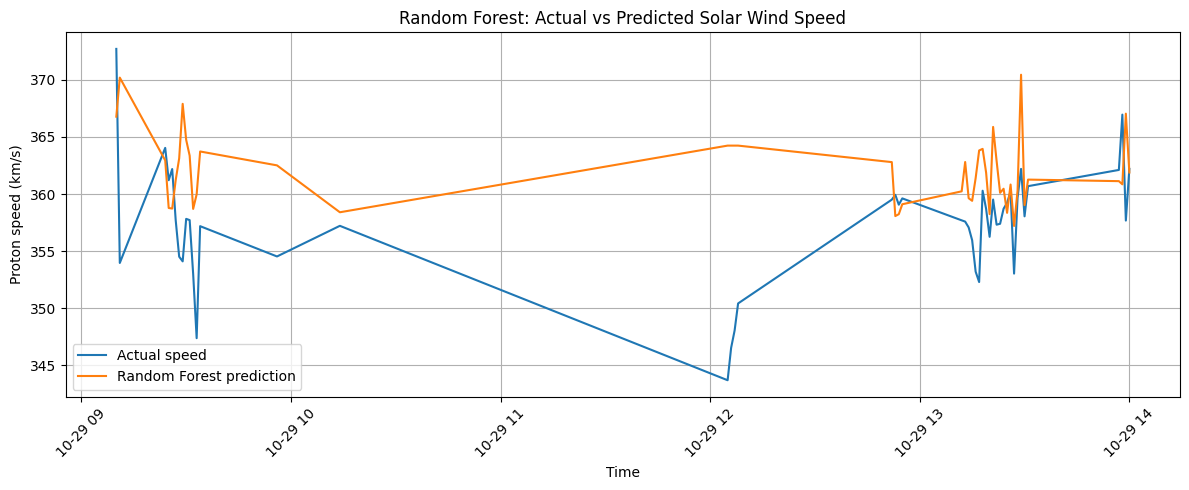

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.index,
    y_test,
    label="Actual speed"
)

plt.plot(
    y_test.index,
    rf_predictions,
    label="Random Forest prediction"
)

plt.xlabel("Time")
plt.ylabel("Proton speed (km/s)")
plt.title("Random Forest: Actual vs Predicted Solar Wind Speed")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Train a Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict the test observations
linear_predictions = linear_model.predict(X_test)

# Calculate the prediction error
linear_mae = mean_absolute_error(
    y_test, linear_predictions
)

print("Linear Regression solar wind prediction")
print("Baseline MAE:", round(baseline_mae_same_test, 2), "km/s")
print("Random Forest MAE:", round(rf_mae, 2), "km/s")
print("Linear Regression MAE:", round(linear_mae, 2), "km/s")

Linear Regression solar wind prediction
Baseline MAE: 3.17 km/s
Random Forest MAE: 5.7 km/s
Linear Regression MAE: 3.45 km/s


In [32]:
# Check the time intervals between measurements

time_gaps = speed.index.to_series().diff()

print("Total observations:", len(speed))
print("Time intervals longer than one minute:",
      (time_gaps > pd.Timedelta(minutes=1)).sum())

print("\nLargest time intervals:")
print(time_gaps.sort_values(ascending=False).head(10))

Total observations: 1434
Time intervals longer than one minute: 0

Largest time intervals:
2026-10-28 14:16:00   0 days 00:01:00
2026-10-29 05:57:00   0 days 00:01:00
2026-10-29 06:17:00   0 days 00:01:00
2026-10-29 06:16:00   0 days 00:01:00
2026-10-29 06:15:00   0 days 00:01:00
2026-10-29 06:14:00   0 days 00:01:00
2026-10-29 06:13:00   0 days 00:01:00
2026-10-29 06:12:00   0 days 00:01:00
2026-10-29 06:11:00   0 days 00:01:00
2026-10-29 06:10:00   0 days 00:01:00
dtype: timedelta64[ns]
